In [3]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Buscar phone.csv desde el directorio actual hacia arriba
directorio_actual = Path.cwd()

ruta_phone = None

for carpeta in [directorio_actual, *directorio_actual.parents]:
    candidata = carpeta / "data" / "raw" / "phone.csv"

    if candidata.is_file():
        ruta_phone = candidata
        break

if ruta_phone is None:
    raise FileNotFoundError(
        "No se encontró data/raw/phone.csv. "
        f"Directorio actual: {directorio_actual}"
    )

# Cargar sin modificar el CSV original
phone = pd.read_csv(ruta_phone)

print("Archivo encontrado:", ruta_phone)
print("Dimensiones:", phone.shape)
print("\nColumnas:", phone.columns.tolist())

print("\nInformación estructural:")
phone.info()

print("\nPrimeros registros:")
display(phone.head())




Archivo encontrado: e:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\data\raw\phone.csv
Dimensiones: (6361, 2)

Columnas: ['customerID', 'MultipleLines']

Información estructural:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB

Primeros registros:


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


In [4]:

# Distribución del servicio MultipleLines

resumen_phone = (
    phone["MultipleLines"]
    .value_counts()
    .rename_axis("MultipleLines")
    .reset_index(name="clientes")
)

resumen_phone["porcentaje"] = (
    resumen_phone["clientes"] / len(phone) * 100
).round(2)

display(resumen_phone)


,MultipleLines,clientes,porcentaje
0,No,3390,53.29
1,Yes,2971,46.71


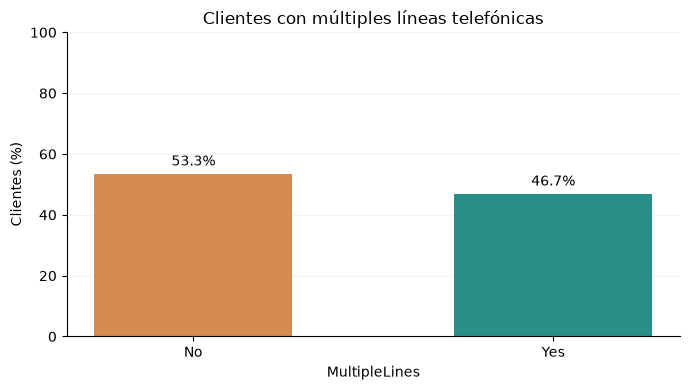

In [5]:

import matplotlib.pyplot as plt

colores = {
    "Yes": "#278F88",
    "No": "#D58B52"
}

fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(
    resumen_phone["MultipleLines"],
    resumen_phone["porcentaje"],
    color=[
        colores[x] for x in resumen_phone["MultipleLines"]
    ],
    width=0.55
)

ax.bar_label(barras, fmt="%.1f%%", padding=4)

ax.set_title("Clientes con múltiples líneas telefónicas")
ax.set_xlabel("MultipleLines")
ax.set_ylabel("Clientes (%)")
ax.set_ylim(0, 100)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
